### Installing required libraries

In [4]:
# Install required libraries
!pip install seaborn missingno xgboost catboost regex scikit-learn pandas numpy imblearn lightgbm polars shap


### Importing all libraries 

In [5]:
# Core libraries
import pandas as pd
import numpy as np
import csv
import re

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# Preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.utils import resample

# Model selection
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

# Models
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import xgboost as xgb

# Metrics
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    make_scorer
)


### Import additional items as needed...

In [6]:
# Model selection utilities
from sklearn.model_selection import (
    KFold,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_score
)

# Preprocessing & pipelines
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import make_pipeline

# Models & balancing
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from imblearn.over_sampling import SMOTE

# Metrics (only those not already imported in Script 2)
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score
)

# Plotly visualization
import plotly
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
from plotly.offline import iplot
from plotly.subplots import make_subplots
import plotly.figure_factory as ff

# Suppress warnings
import warnings
warnings.filterwarnings("ignore")


### Loading CSV data 

In [7]:
diabetes = pd.read_csv('raw/diabetic_data.csv')

# CLEANING AND TRANSFORMING THE DATASET

In [8]:
print(diabetes.columns)

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='str')


In [9]:
for g in diabetes['gender'].unique():
    col = f"Gender_{g}"
    diabetes[col] = (diabetes['gender'] == g).astype(int)


In [10]:
#@title AGE ENCODING
# Convert everything to string and strip spaces
diabetes['age'] = diabetes['age'].astype(str).str.strip()

# Mapping age ranges to numeric midpoint values
age_map = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}

# Apply mapping
diabetes['age'] = diabetes['age'].map(age_map)

In [11]:
# Mapping Admission Type ID to interpretable binary categories:
# 1 = Emergency/Urgent/Trauma
# 0 = Elective/Newborn/NotAvailable/NULL/NotMapped

admission_type_binary_map = {
    1: 1,  # Emergency
    2: 1,  # Urgent
    7: 1,  # TraumaCenter

    3: 0,  # Elective
    4: 0,  # Newborn
    5: 0,  # NotAvailable
    6: 0,  # NULL
    8: 0   # NotMapped
}

diabetes["admission_emergency"] = (
    diabetes["admission_type_id"]
    .map(admission_type_binary_map)
    .fillna(0)
    .astype(int)
)


In [12]:
# Binary mapping for discharge disposition:
# 0 = routine / lower‑risk discharge
# 1 = adverse / higher‑risk discharge

discharge_disposition_binary_map = {
    # lower‑risk / routine
    11: 0,  # Expired
    12: 0,  # StillPatient
    13: 0,  # HospiceHome   
    14: 0,  # HospiceFacility
    15: 0,  # SwingBed
    19: 0,  # ExpiredHomeMedicaid
    20: 0,  # ExpiredFacilityMedicaid
    21: 0,  # ExpiredUnknownMedicaid
   
    # posible higher‑risk / adverse outcomes
    1: 1,   # Home
    2: 1,   # ShortTermHospital
    3: 1,   # SNF
    4: 1,   # ICF
    5: 1,   # OtherInpatientCare
    6: 1,   # HomeHealth
    7: 1,   # LeftAMA
    8: 1,   # HomeIVCare
    9: 1,   # AdmittedToThisHospital
    10: 1,  # NeonateToAnotherHospital
    16: 1,  # OutpatientServicesOtherInstitution
    17: 1,  # OutpatientServicesThisInstitution
    18: 1,  # NULL
    22: 1,  # RehabFacility
    23: 1,  # LongTermCareHospital
    24: 1,  # MedicaidNursingFacility
    25: 1,  # NotMapped
    27: 1,  # FederalHealthCareFacility
    28: 1,  # PsychiatricHospital
    29: 1,  # CriticalAccessHospital
    30: 1,   # OtherHealthcareInstitution
    
}

diabetes["DischargeRisk"] = (
    diabetes["discharge_disposition_id"]
        .map(discharge_disposition_binary_map)
        .fillna(0)
        .astype(int)
)


In [13]:
def icd_to_chapter(code):
    # Handle missing or non-numeric codes
    try:
        code = float(code)
    except:
        return "Unknown"

    if 1 <= code <= 139:
        return "Infectious and Parasitic Diseases"
    elif 140 <= code <= 239:
        return "Neoplasms"
    elif 240 <= code <= 279:
        return "Endocrine/Metabolic"
    elif 280 <= code <= 289:
        return "Blood Diseases"
    elif 290 <= code <= 319:
        return "Mental Disorders"
    elif 320 <= code <= 389:
        return "Nervous System"
    elif 390 <= code <= 459:
        return "Circulatory System"
    elif 460 <= code <= 519:
        return "Respiratory System"
    elif 520 <= code <= 579:
        return "Digestive System"
    elif 580 <= code <= 629:
        return "Genitourinary System"
    elif 630 <= code <= 679:
        return "Pregnancy/Childbirth"
    elif 680 <= code <= 709:
        return "Skin/Subcutaneous"
    elif 710 <= code <= 739:
        return "Musculoskeletal"
    elif 740 <= code <= 759:
        return "Congenital Anomalies"
    elif 760 <= code <= 779:
        return "Perinatal Conditions"
    elif 780 <= code <= 799:
        return "Symptoms/Ill-defined"
    elif 800 <= code <= 999:
        return "Injury/Poisoning"
    elif code >= 1000:
        return "Unknown"
    else:
        return "Unknown"


In [14]:
for col in ["diag_1", "diag_2", "diag_3"]:
    diabetes[col + "_chapter"] = diabetes[col].apply(icd_to_chapter)


In [15]:
# ============================================================
# Binary mapping for ICD diagnosis chapters
# ============================================================
diag_binary_map = {
    "Endocrine/Metabolic": 1,
    "Circulatory System": 1,
    "Respiratory System": 1,
    "Neoplasms": 1,
    "Infectious and Parasitic Diseases": 1,
    "Injury/Poisoning": 1,
    "Genitourinary System": 1,
    "Nervous System": 1,
    "Blood Diseases": 1,
    "Mental Disorders": 1,

    "Symptoms/Ill-defined": 0,
    "Skin/Subcutaneous": 0,
    "Musculoskeletal": 0,
    "Digestive System": 0,
    "Pregnancy/Childbirth": 0,
    "Congenital Anomalies": 0,
    "V-Codes": 0,
    "E-Codes": 0,
    "Unknown": 0
}

for col in ["diag_1_chapter", "diag_2_chapter", "diag_3_chapter"]:
    diabetes[col] = (
        diabetes[col]
            .map(diag_binary_map)
            .fillna(0)
            .astype(int)
    )


In [16]:
#@title DIABEST MEDICATION ENCODING
# replacing No with 0 and Yes with 1 for if the patient has diabetic medications or not
diabetes['diabetesMed'] = diabetes['diabetesMed'].apply(
    lambda x: 1 if str(x).strip().lower() == "yes" else 0
)

In [17]:
#@title READMITTED ENCODING
# Created indicator column for readmission within 30 days
# lessthan30 = 1 if readmitted is "<30", else 0

diabetes['lessthan30'] = (diabetes['readmitted'] == '<30').astype(int)

In [18]:
#@title RACE ENCODING
# Replace '?' with 'Unknown'
diabetes['race'] = diabetes['race'].replace('?', 'Unknown')

# Create binary columns for each race category
for race in diabetes['race'].unique():
    col_name = f"Race_{race}"
    diabetes[col_name] = (diabetes['race'] == race).astype(int)


In [19]:
diabetes.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted',
       'Gender_Female', 'Gender_Male', 'Gender_Unknown/Invalid',
       'admission_emergency

In [20]:
#@title drop 1 intial columns
# Dropping unnecessary columns due to high missing values and low relevance
cleandiabetes = diabetes.drop([
    'encounter_id', 'patient_nbr', 'race', 'gender', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'payer_code', 'medical_specialty', 'diag_1',
       'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'readmitted'
], axis=1)

In [21]:
print(cleandiabetes.columns)

Index(['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'number_diagnoses', 'diabetesMed', 'Gender_Female',
       'Gender_Male', 'Gender_Unknown/Invalid', 'admission_emergency',
       'DischargeRisk', 'diag_1_chapter', 'diag_2_chapter', 'diag_3_chapter',
       'lessthan30', 'Race_Caucasian', 'Race_AfricanAmerican', 'Race_Unknown',
       'Race_Other', 'Race_Asian', 'Race_Hispanic'],
      dtype='str')


In [22]:
numerical = [ 'time_in_hospital', #age removed --- IGNORE ---
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_emergency',
    'number_outpatient',
    'number_inpatient',
    'number_diagnoses' ]

### MISSING DATA

In [23]:
def missing(df):
    missing_number = df.isnull().sum().sort_values(ascending=False)
    missing_percent = (df.isnull().sum() / df.isnull().count()).sort_values(ascending=False)
    missing_values = pd.concat([missing_number, missing_percent], axis=1,
                               keys=['Missing_Number', 'Missing_Percent'])
    return missing_values

In [24]:
print("Missing Data in Sub1:")
display(missing(cleandiabetes))



Missing Data in Sub1:


,Missing_Number,Missing_Percent
age,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
number_outpatient,0,0.0
number_emergency,0,0.0
number_inpatient,0,0.0
number_diagnoses,0,0.0
diabetesMed,0,0.0


### CORRELATION

In [25]:
#@title Correlation Matrices
print("Correlation Matrix for Sub1")
display(cleandiabetes[numerical].corr())

Correlation Matrix for Sub1


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_emergency,number_outpatient,number_inpatient,number_diagnoses
time_in_hospital,1.000000,0.318450,0.191472,0.466135,-0.009681,-0.008916,0.073623,0.220186
num_lab_procedures,0.318450,1.000000,0.058066,0.268161,-0.002279,-0.007602,0.039231,0.152773
num_procedures,0.191472,0.058066,1.000000,0.385767,-0.038179,-0.024819,-0.066236,0.073734
num_medications,0.466135,0.268161,0.385767,1.000000,0.013180,0.045197,0.064194,0.261526
number_emergency,-0.009681,-0.002279,-0.038179,0.013180,1.000000,0.091459,0.266559,0.055539
number_outpatient,-0.008916,-0.007602,-0.024819,0.045197,0.091459,1.000000,0.107338,0.094152
number_inpatient,0.073623,0.039231,-0.066236,0.064194,0.266559,0.107338,1.000000,0.104710
number_diagnoses,0.220186,0.152773,0.073734,0.261526,0.055539,0.094152,0.104710,1.000000


In [26]:
print("Correlation for lessthan30 grouped by readmit_less_30")
display(cleandiabetes.groupby('lessthan30')[numerical].corr())


Correlation for lessthan30 grouped by readmit_less_30


time_in_hospital  num_lab_procedures  \
lessthan30                                                            
0          time_in_hospital            1.000000            0.317989   
           num_lab_procedures          0.317989            1.000000   
           num_procedures              0.184408            0.052895   
           num_medications             0.463444            0.263560   
           number_emergency           -0.003926            0.004755   
           number_outpatient          -0.008024           -0.009675   
           number_inpatient            0.081368            0.044145   
           number_diagnoses            0.222780            0.153492   
1          time_in_hospital            1.000000            0.317655   
           num_lab_procedures          0.317655            1.000000   
           num_procedures              0.256572            0.104734   
           num_medications             0.479381            0.300945   
           number_emergency           -0.054951           -0.046064   
           number_outpatient          -0.022948            0.005296   
           number_inpatient            0.011970            0.004974   
           number_diagnoses            0.182704            0.138825   

                               num_procedures  num_medications  \
lessthan30                                                       
0          time_in_hospital          0.184408         0.463444   
           num_lab_procedures        0.052895         0.263560   
           num_procedures            1.000000         0.385410   
           num_medications           0.385410         1.000000   
           number_emergency         -0.036945         0.017058   
           number_outpatient        -0.023123         0.044063   
           number_inpatient         -0.063114         0.066989   
           number_diagnoses          0.071852         0.261229   
1          time_in_hospital          0.256572         0.479381   
           num_lab_procedures        0.104734         0.300945   
           num_procedures            1.000000         0.396435   
           num_medications           0.396435         1.000000   
           number_emergency         -0.044692        -0.019015   
           number_outpatient        -0.036554         0.048016   
           number_inpatient         -0.084559         0.028102   
           number_diagnoses          0.098215         0.251496   

                               number_emergency  number_outpatient  \
lessthan30                                                           
0          time_in_hospital           -0.003926          -0.008024   
           num_lab_procedures          0.004755          -0.009675   
           num_procedures             -0.036945          -0.023123   
           num_medications             0.017058           0.044063   
           number_emergency            1.000000           0.091215   
           number_outpatient           0.091215           1.000000   
           number_inpatient            0.241279           0.106598   
           number_diagnoses            0.056901           0.093659   
1          time_in_hospital           -0.054951          -0.022948   
           num_lab_procedures         -0.046064           0.005296   
           num_procedures             -0.044692          -0.036554   
           num_medications            -0.019015           0.048016   
           number_emergency            1.000000           0.094259   
           number_outpatient           0.094259           1.000000   
           number_inpatient            0.316596           0.113480   
           number_diagnoses            0.036837           0.091372   

                               number_inpatient  number_diagnoses  
lessthan30                                                         
0          time_in_hospital            0.081368          0.222780  
           num_lab_procedures          0.044145          0.153492  
           num_procedures     

In [27]:
#@title Reusable Correlation Heatmaps
def plot_corr_heatmap(df, numerical, title):
    """
    Plots a lower‑triangle correlation heatmap for a given dataframe.
    """
    corr_matrix = df[numerical].corr()

    # Mask upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap='coolwarm',
        center=0,
        square=True,
        linewidths=0.5,
        fmt='.2f',
        mask=mask
    )

    plt.title(title, fontsize=14)
    plt.tight_layout()
    plt.show()


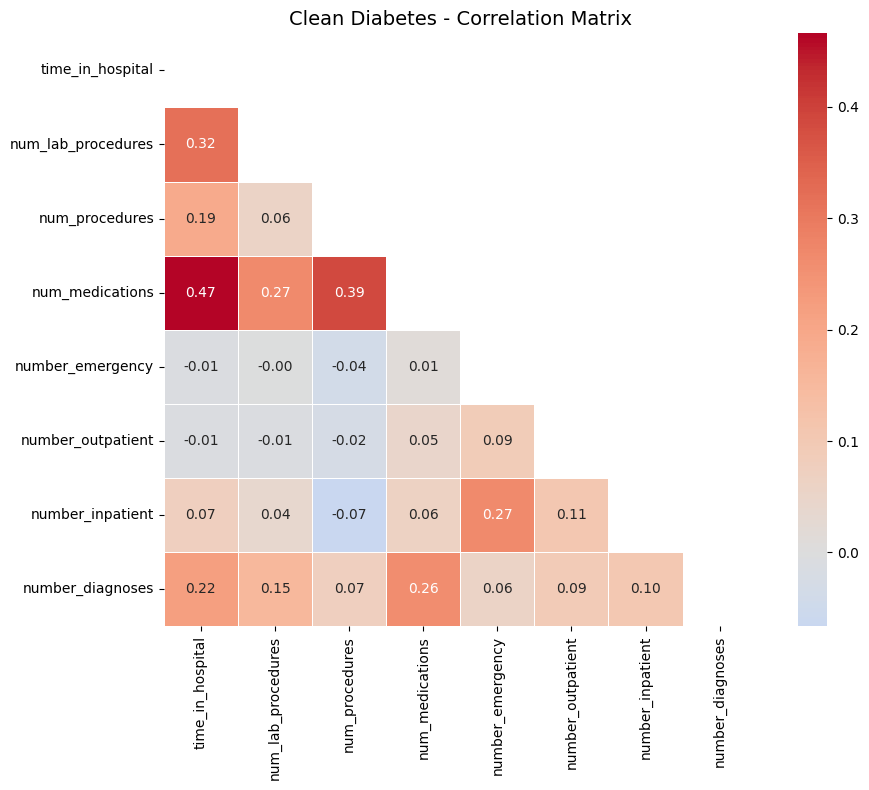

In [28]:
plot_corr_heatmap(cleandiabetes, numerical, "Clean Diabetes - Correlation Matrix")


## Breaking the data up into Train & Test

In [29]:
#@title Setting Up Data for Modeling 
#Uses the cleandiabetes dataset for modeling.
DataTesting = cleandiabetes.copy() #change it to sub2 or Sub3 to test each dataset

In [30]:
# Step 1: Split cleandiabetes into Train (70%) and Temp (30%)
train_df, temp_df = train_test_split(
    DataTesting,
    test_size=0.30,        # 30% goes to temp (valid + test)
    random_state=42,       # ensures reproducibility
    shuffle=True           # shuffles before splitting
)


# Step 2: Split Temp into Validation (15%) and Test (15%)
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,        # half of temp = 15% of total
    random_state=42,
    shuffle=True
)

# Step 3: Reset indexes for cleanliness
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)


# Step 4: Just Making Sure Check
print("Train size:", len(train_df))
print("Validation size:", len(valid_df))
print("Test size:", len(test_df))
print("Total:", len(train_df) + len(valid_df) + len(test_df))


Train size: 71236
Validation size: 15265
Test size: 15265
Total: 101766


In [31]:
DataTesting.lessthan30.value_counts()

lessthan30
0    90409
1    11357
Name: count, dtype: int64

In [32]:
train_df.lessthan30.value_counts()

lessthan30
0    63304
1     7932
Name: count, dtype: int64

In [33]:
valid_df.lessthan30.value_counts()

lessthan30
0    13500
1     1765
Name: count, dtype: int64

In [34]:
test_df.lessthan30.value_counts()

lessthan30
0    13605
1     1660
Name: count, dtype: int64

## Ways to Fix/Treat the Imbalance in the Data
Imbalance in the data means that one of the classes in the data is too less as compared to the others. Typically, it is better to balance the data in some way to give the positives more weight. There are 3 strategies that are typically utilized:

#### 1. RANDOM OVERSAMPLING: 
This technique involves randomly duplicating examples from the minority class in the training dataset. 
This can help balance the class distribution but may lead to overfitting since it replicates existing data points.

In [35]:
def balance_random_oversample(df, target='readmit_less_30', random_state=42):
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    df_pos_over = resample(
        df_pos,
        replace=True,
        n_samples=len(df_neg),
        random_state=random_state
    )

    df_bal = (
        pd.concat([df_neg, df_pos_over])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### 2. SMOTE 
(Synthetic Minority Over-sampling Technique): SMOTE generates synthetic examples of the minority class by interpolating between existing minority class examples. 
This can help create a more balanced dataset without simply duplicating existing data points, which may reduce the risk of overfitting compared to random oversampling.

In [36]:
def balance_smote(df, target='readmit_less_30', random_state=42):
    X = df.drop(columns=[target])
    y = df[target]

    sm = SMOTE(random_state=random_state)
    X_res, y_res = sm.fit_resample(X, y)

    df_bal = pd.concat(
        [pd.DataFrame(X_res, columns=X.columns),
         pd.Series(y_res, name=target)],
        axis=1
    )

    return df_bal

#### 3. RANDOM UNDERSAMPLING
Random Undersampling reduces the size of the majority class by randomly removing samples until it matches the minority class count. This creates a balanced dataset without generating synthetic data.

In [37]:
def balance_random_undersample(df, target='readmit_less_30', random_state=42):
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    df_neg_under = df_neg.sample(
        n=len(df_pos),
        random_state=random_state
    )

    df_bal = (
        pd.concat([df_pos, df_neg_under])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### 4. SMOTEENN


In [38]:
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTE
# SMOTEENN is a powerful hybrid method that combines SMOTE oversampling with ENN (Edited Nearest Neighbors) undersampling to both balance the classes and clean the data by removing noisy samples.
# higher recall than smote alone, but can be more aggressive in removing samples, which may lead to a smaller dataset and potential loss of information. It is often more effective when the dataset has a lot of noise or borderline samples.
def apply_smoteenn(X, y, k_neighbors=5, random_state=42):
    """
    Apply SMOTEENN hybrid resampling:
    - SMOTE oversamples the minority class
    - ENN removes noisy majority samples

    Returns:
        X_resampled, y_resampled
    """
    smote = SMOTE(k_neighbors=k_neighbors, random_state=random_state)
    smote_enn = SMOTEENN(smote=smote, random_state=random_state)

    X_resampled, y_resampled = smote_enn.fit_resample(X, y)
    return X_resampled, y_resampled

#### 5. SMOTETOMEK

In [39]:
from imblearn.combine import SMOTETomek
# SMOTETomek is another hybrid method that combines SMOTE oversampling with Tomek Links undersampling to clean the data.
# More balanced than SMOTEENN, as Tomek Links specifically target borderline samples, while ENN can be more aggressive in removing samples.
def apply_smotetomek(X, y, k_neighbors=5, random_state=42):
    """
    Apply SMOTETomek hybrid resampling:
    - SMOTE oversamples the minority class
    - Tomek Links remove borderline/noisy majority samples

    Returns:
        X_resampled, y_resampled
    """
    smote = SMOTE(k_neighbors=k_neighbors, random_state=random_state)
    smote_tomek = SMOTETomek(smote=smote, random_state=random_state)

    X_resampled, y_resampled = smote_tomek.fit_resample(X, y)
    return X_resampled, y_resampled


#### Prevalence Caculation Function

In [40]:
def calc_prevalence(y_actual):
    """
    Calculate the prevalence (ratio of positive class = 1)
    in a binary target array or Series.
    """
    y_actual = pd.Series(y_actual)
    return y_actual.mean()

<h2 style="color:#e63946;">CHANGE THE IMBALANCE TECHNIQUE HERE</h2>
“Remove the # to activate a specific technique."


In [41]:
# 1. Split train_df into X and y
X_train = train_df.drop(columns=["lessthan30"])
y_train = train_df["lessthan30"]

# 2. Apply SMOTEENN to balance the training data 
# experiment with different method teqniques (SMOTE, random oversampling, random undersampling, SMOTEENN, SMOTETomek)
X_bal, y_bal = apply_smoteenn(X_train, y_train)

# 3. Combine back into a single DataFrame (optional)
train_balanced = X_bal.copy()
train_balanced["lessthan30"] = y_bal

# 4. Check prevalence
print(
    "Train balanced prevalence (n = %d): %.3f" %
    (len(train_balanced), calc_prevalence(train_balanced['lessthan30']))
)


Train balanced prevalence (n = 90794): 0.637


In [42]:
train_balanced.lessthan30.value_counts()

lessthan30
1    57858
0    32936
Name: count, dtype: int64

In [43]:
# remove the target variable from the training, validation, and test sets and store it separately for modeling.
# x represents the features (independent variables) used for training the model, while y represents the target variable (dependent variable) that the model is trying to predict.

X_train = train_balanced.drop('lessthan30',axis=1)

y_train = train_balanced['lessthan30']

X_valid = valid_df.drop('lessthan30',axis=1)

y_valid = valid_df['lessthan30']

X_test = test_df.drop('lessthan30',axis=1)

y_test = test_df['lessthan30']

<h2 style="color:#e63946;">CHANGE THE SETS HERE FOR SCALER</h2>

In [44]:
scale_cols = numerical
# -----------------------------------------
# 1. Fit the scaler on TRAINING data only
# -----------------------------------------
scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])

# -----------------------------------------
# 2. Transform VALIDATION and TEST sets
# -----------------------------------------
X_valid[scale_cols] = scaler.transform(X_valid[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])


In [45]:
X_train.head()

,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,diabetesMed,...,DischargeRisk,diag_1_chapter,diag_2_chapter,diag_3_chapter,Race_Caucasian,Race_AfricanAmerican,Race_Unknown,Race_Other,Race_Asian,Race_Hispanic
0,85,1.948662,0.072162,-0.722736,-0.276192,-0.257972,-0.191606,-0.508497,0.856685,1,...,1,1,1,1,1,0,0,0,0,0
1,85,-1.157091,-0.338617,0.544979,-1.147494,-0.257972,-0.191606,-0.508497,-1.315279,0,...,1,1,0,0,1,0,0,0,0,0
2,65,1.258495,0.072162,-0.722736,0.968525,-0.257972,0.814447,2.246885,0.856685,1,...,1,1,1,1,1,0,0,0,0,0
3,65,2.638830,0.380246,-0.722736,-0.525135,-0.257972,-0.191606,-0.508497,-0.229297,1,...,1,1,1,1,1,0,0,0,0,0
4,65,-0.121840,-1.262871,3.080410,-0.151720,-0.257972,-0.191606,-0.508497,0.313694,1,...,1,1,1,1,1,0,0,0,0,0


In [46]:
X_train.head().T

,0,1,2,3,4
age,85.000000,85.000000,65.000000,65.000000,65.000000
time_in_hospital,1.948662,-1.157091,1.258495,2.638830,-0.121840
num_lab_procedures,0.072162,-0.338617,0.072162,0.380246,-1.262871
num_procedures,-0.722736,0.544979,-0.722736,-0.722736,3.080410
num_medications,-0.276192,-1.147494,0.968525,-0.525135,-0.151720
number_outpatient,-0.257972,-0.257972,-0.257972,-0.257972,-0.257972
number_emergency,-0.191606,-0.191606,0.814447,-0.191606,-0.191606
number_inpatient,-0.508497,-0.508497,2.246885,-0.508497,-0.508497
number_diagnoses,0.856685,-1.315279,0.856685,-0.229297,0.313694
diabetesMed,1.000000,0.000000,1.000000,1.000000,1.000000


## Creating and Understanding Models

In [47]:
#@title Evaluation Metrics Function 
def calc_specificity(y_actual, y_pred, thresh):
    # calculates specificity
    return sum((y_pred < thresh) & (y_actual == 0)) /sum(y_actual ==0)

def print_report(y_actual, y_pred, thresh = 0.5):
    
    '''
    This function calculates all the metrics to asses the machine learning models.
    
    Params:
    1. y_actual: The actual values for the target variable.
    2. y_pred: The predicted values for the target variable.
    3. thresh: The threshold for the probability to be considered as a positive class. Default value 0.5
    
    Return:
    1. AUC - ROC Curve # AUC (Area Under the Curve) for the ROC (Receiver Operating Characteristic) curve, which measures the model's ability to distinguish between classes across all thresholds.
    2. Accuracy # True Positive + True Negative / Total
    3. Recall # True Positive Rate
    4. Precision # True Positive Rate
    5. Specificity # True Negative Rate
    '''
    
    auc = roc_auc_score(y_actual, y_pred)
    accuracy = accuracy_score(y_actual, (y_pred > thresh))
    recall = recall_score(y_actual, (y_pred > thresh))
    precision = precision_score(y_actual, (y_pred > thresh))
    specificity = calc_specificity(y_actual, y_pred, thresh)
    print('AUC:%.3f'%auc)
    print('accuracy:%.3f'%accuracy)
    print('recall:%.3f'%recall)
    print('precision:%.3f'%precision)
    print('specificity:%.3f'%specificity)
    print('prevalence:%.3f'%calc_prevalence(y_actual))
    print(' ')
    return auc, accuracy, recall, precision, specificity

### Linear Regression

In [48]:
# disable truncation so NumPy prints the entire array
np.set_printoptions(threshold=np.inf)

lnr = LinearRegression()
lnr.fit(X_train, y_train)

y_valid_preds = lnr.predict(X_valid)

In [49]:
print(y_valid_preds)

[ 0.60316978  0.49643262  0.36006077  0.12896163  0.41266232  0.61240725
  0.57068319  0.58363447  0.30930032  0.50719699  0.49355606  0.26530061
  0.53790501  0.55243986  0.45908669  0.37911043  0.45479462  0.37822131
  0.60724654  0.41027773  0.56973826  0.72031363  0.62555598  0.46680545
  0.48515289  0.59392085  0.27931337  0.66485712  0.72540549  0.60876673
  0.49994805  0.28269154  0.15581869  0.26672172  0.47667758  0.69594098
  0.52716644  0.6461318   0.481071    0.59350874  0.50770059  0.61113638
  0.49642584  0.19378407  0.53155919  0.42496768  0.52044561  0.4659964
  0.45704463  0.41428422  0.37761748  0.72530241  0.593493    0.45237042
  0.2086873   0.5469433  -0.03771596  0.10166896  0.19439089  0.71338313
  0.45802918  0.53508177  0.33735074  0.72722214  0.56262412  0.41349886
  0.21596011  0.6609409   0.56832621  0.37646417  0.22253864  0.51008812
  0.52723315  0.25054971  0.26613268  0.27393677  0.58414422  0.47040853
  0.49408113  0.523129    0.38862042  0.5337275   0.

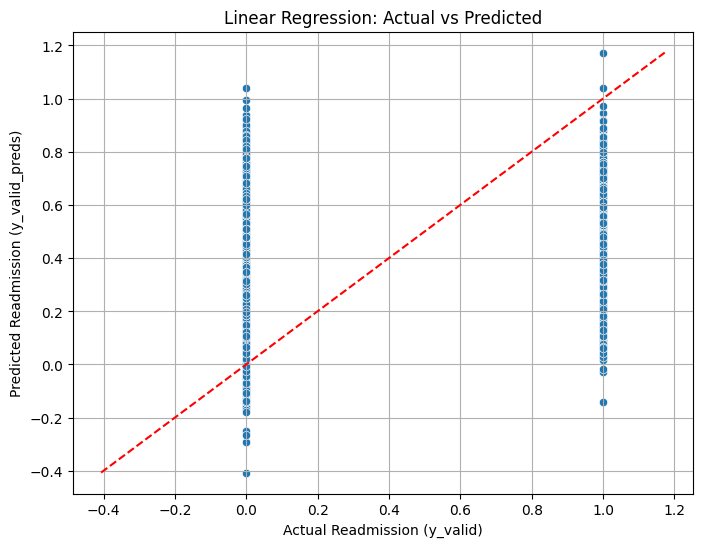

In [50]:
# Create a scatter plot of Actual vs Predicted
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_valid, y=y_valid_preds)

# Add a 45-degree reference line
min_val = min(y_valid.min(), y_valid_preds.min())
max_val = max(y_valid.max(), y_valid_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.xlabel("Actual Readmission (y_valid)")
plt.ylabel("Predicted Readmission (y_valid_preds)")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(True)
plt.show()


### Logistic Regression

In [51]:
lr=LogisticRegression(random_state = 42, solver = 'newton-cg', max_iter = 200)
lr.fit(X_train, y_train)

y_valid_preds = lr.predict_proba(X_valid)[:,1]

print('Metrics for Validation data:')

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,y_valid_preds, 0.5)

Metrics for Validation data:
AUC:0.569
accuracy:0.672
recall:0.381
precision:0.147
specificity:0.710
prevalence:0.116
 


### KNN Model

In [52]:
knn = KNeighborsClassifier(n_neighbors = 100)
knn.fit(X_train, y_train)

knn_preds = knn.predict_proba(X_valid)[:,1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,knn_preds, 0.5)

AUC:0.566
accuracy:0.476
recall:0.615
precision:0.129
specificity:0.438
prevalence:0.116
 


### Stochastic Gradient Descent Model

In [53]:
sgdc = SGDClassifier(loss='log_loss', alpha=0.1, random_state=42)
sgdc.fit(X_train, y_train)

sgd_preds = sgdc.predict_proba(X_valid)[:, 1]

print('Stochastic Gradient Descent')
print('Validation:')
sgdc_valid_auc, sgdc_valid_accuracy, sgdc_valid_recall, \
sgdc_valid_precision, sgdc_valid_specificity = print_report(y_valid, sgd_preds, 0.5)

Stochastic Gradient Descent
Validation:
AUC:0.577
accuracy:0.353
recall:0.785
precision:0.127
specificity:0.296
prevalence:0.116
 


### Decision Tree

In [54]:
dc_clf = DecisionTreeClassifier(random_state=42, max_depth = 10)
dc_clf.fit(X_train, y_train)

dc_preds_proba = dc_clf.predict_proba(X_valid)[:,1]
dc_preds = dc_clf.predict(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,dc_preds_proba, 0.5)

AUC:0.551
accuracy:0.649
recall:0.382
precision:0.136
specificity:0.682
prevalence:0.116
 


### Random Forest

In [55]:
rf_clf = RandomForestClassifier(random_state=111, max_depth = 6)

rf_clf.fit(X_train, y_train)

rf_preds = rf_clf.predict(X_valid)
rf_preds_proba = rf_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,rf_preds_proba, 0.5)

AUC:0.556
accuracy:0.356
recall:0.755
precision:0.124
specificity:0.303
prevalence:0.116
 


### Linear SVC

In [56]:
lsvc_clf = LinearSVC(random_state=111)
lsvc_clf.fit(X_train, y_train)

lsvc_preds = lsvc_clf.decision_function(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,lsvc_preds, 0.5)

AUC:0.568
accuracy:0.868
recall:0.063
precision:0.234
specificity:0.973
prevalence:0.116
 


### Gradient Boosting Model

In [57]:
gb_clf = GradientBoostingClassifier(n_estimators = 100, criterion='friedman_mse', learning_rate = 1.0, max_depth = 3,\
                                    random_state = 111)

gb_clf.fit(X_train, y_train)
gb_preds = gb_clf.predict(X_valid)
gb_preds_proba = gb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,gb_preds_proba, 0.5)

AUC:0.573
accuracy:0.673
recall:0.381
precision:0.147
specificity:0.711
prevalence:0.116
 


### XGB Model

In [58]:
xgb_clf = xgb.XGBClassifier(max_depth=3, learning_rate = 1.0, use_label_encoder = False,\
                            eval_metric = 'logloss')
xgb_clf.fit(X_train, y_train)

xgb_preds = xgb_clf.predict(X_valid)
xgb_preds_proba = xgb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,xgb_preds_proba, 0.5)

AUC:0.575
accuracy:0.676
recall:0.380
precision:0.148
specificity:0.715
prevalence:0.116
 


### Catboost Model

In [59]:
catb=CatBoostClassifier(iterations=200, depth=3, learning_rate=1.0, random_state = 111)
catb.fit(X_train, y_train)
catb_preds = catb.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,catb_preds, 0.5)

0:	learn: 0.5869956	total: 163ms	remaining: 32.4s
1:	learn: 0.4822039	total: 169ms	remaining: 16.7s
2:	learn: 0.4537489	total: 174ms	remaining: 11.4s
3:	learn: 0.4368709	total: 180ms	remaining: 8.82s
4:	learn: 0.4264557	total: 185ms	remaining: 7.2s
5:	learn: 0.4199273	total: 190ms	remaining: 6.13s
6:	learn: 0.4130803	total: 196ms	remaining: 5.39s
7:	learn: 0.4077391	total: 199ms	remaining: 4.79s
8:	learn: 0.4023215	total: 204ms	remaining: 4.32s
9:	learn: 0.3993792	total: 209ms	remaining: 3.97s
10:	learn: 0.3953281	total: 213ms	remaining: 3.66s
11:	learn: 0.3937790	total: 219ms	remaining: 3.42s
12:	learn: 0.3916645	total: 224ms	remaining: 3.22s
13:	learn: 0.3904334	total: 230ms	remaining: 3.05s
14:	learn: 0.3892094	total: 234ms	remaining: 2.89s
15:	learn: 0.3871680	total: 238ms	remaining: 2.74s
16:	learn: 0.3853165	total: 244ms	remaining: 2.63s
17:	learn: 0.3843865	total: 248ms	remaining: 2.51s
18:	learn: 0.3832564	total: 253ms	remaining: 2.41s
19:	learn: 0.3821553	total: 260ms	remainin

## Hyper Parameter Tuning

### Decision Tree

In [60]:
# Decision Tree - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

dc_grid = {'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'min_samples_leaf': range(1, 11, 2), ###  -->> Added a critical param
           'criterion':['gini','entropy']} # criterion for evaluating a split

dc_random = RandomizedSearchCV(estimator = dc_clf, param_distributions = dc_grid,
                               n_iter = 20,
                               cv = 10,              ### -->> chnaged cv from 2 to 5
                               scoring ='recall',   ### -->> changed fromscoring=recall_scoring,
                               verbose = 1, random_state = 111)

dc_random.fit(X_train, y_train)

dc_random.best_params_

dc_hp_preds = dc_random.best_estimator_.predict(X_valid)
dc_hp_preds_proba = dc_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, dc_hp_preds_proba)

# added later
print("Best params:", dc_random.best_params_)
print("Best CV recall:", dc_random.best_score_)
print("Validation recall:", recall_score(y_valid, dc_random.best_estimator_.predict(X_valid)))

"""
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}
Best CV recall: 0.8327703475995127
Validation recall: 0.996244131455399

add all metrics from above
"""

Fitting 10 folds for each of 20 candidates, totalling 200 fits
Best params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}
Best CV recall: 1.0
Validation recall: 1.0


"\nFitting 5 folds for each of 20 candidates, totalling 100 fits\nBest params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}\nBest CV recall: 0.8327703475995127\nValidation recall: 0.996244131455399\n\nadd all metrics from above\n"

In [61]:

recall_score(y_valid, dc_hp_preds)

1.0

### Random Forest

In [62]:
# Random Forest - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

rf_grid = {'n_estimators':range(200,1000,200), # number of trees
           'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'criterion':['gini','entropy']} # criterion for evaluating a split

rf_random = RandomizedSearchCV(estimator = rf_clf, param_distributions = rf_grid,
                               n_iter = 20, cv = 2, scoring=recall_scoring,
                               verbose = 1, random_state = 111)

rf_random.fit(X_train, y_train)

rf_random.best_params_

rf_hp_preds = rf_random.best_estimator_.predict(X_valid)
rf_hp_preds_proba = rf_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, rf_hp_preds_proba)

Fitting 2 folds for each of 20 candidates, totalling 40 fits


0.5241058440877138

In [63]:

recall_score(y_valid, dc_hp_preds)

1.0

### XGBoost

In [64]:
#xgboost - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

xgb_grid = params = {
        'min_child_weight': [1, 5, 8, 10],
        'gamma': [0.5, 1, 1.5, 2, 5],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 0.9, 1.0],
        'max_depth': [3, 4, 5]
        } # criterion for evaluating a split

xgb_random = GridSearchCV(estimator = xgb_clf, param_grid = xgb_grid,
                               cv = 2, scoring = recall_scoring,
                               verbose = 1)

xgb_random.fit(X_train, y_train)

xgb_random.best_params_

xgb_hp_preds = xgb_random.best_estimator_.predict(X_valid)
xgb_hp_preds_proba = xgb_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, xgb_hp_preds_proba)

Fitting 2 folds for each of 720 candidates, totalling 1440 fits


0.5681511908509076

In [65]:

recall_score(y_valid, dc_hp_preds)

1.0

#### 4. SAVING PKL MODEL

In [66]:
import joblib
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, accuracy_score, confusion_matrix

# ============================================================
# TARGET
# ============================================================
target = "lessthan30"

print("\n" + "="*70)
print(f"     RANDOM FOREST — FINAL MODEL ({target.upper()}) ")
print("="*70)

prev = y_valid.mean()

# ============================================================
# TRAIN RANDOM FOREST
# ============================================================
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    min_samples_split=2,
    random_state=111,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# ============================================================
# PREDICT PROBABILITIES
# ============================================================
preds_proba = rf.predict_proba(X_valid)[:, 1]

# ============================================================
# METRICS
# ============================================================
auc = roc_auc_score(y_valid, preds_proba)

preds = (preds_proba >= 0.5).astype(int)

acc = accuracy_score(y_valid, preds)
rec = recall_score(y_valid, preds)
prec = precision_score(y_valid, preds)

tn, fp, fn, tp = confusion_matrix(y_valid, preds).ravel()
spec = tn / (tn + fp)

# ============================================================
# PRINT RESULTS
# ============================================================
print("\nValidation Metrics (Random Forest):")
print("-"*50)
print(f"AUC:          {auc:.4f}")
print(f"Accuracy:     {acc:.4f}")
print(f"Recall:       {rec:.4f}")
print(f"Precision:    {prec:.4f}")
print(f"Specificity:  {spec:.4f}")
print(f"Prevalence:   {prev:.4f}")
print("="*70)

# ============================================================
# SAVE MODEL
# ============================================================
filename = f"{target}_RandomForest_Final.Smoteenn.pkl"
joblib.dump(rf, filename)

print(f"Saved Random Forest model as '{filename}'")
print("="*70 + "\n")

final_models = {target: rf}



     RANDOM FOREST — FINAL MODEL (LESSTHAN30) 

Validation Metrics (Random Forest):
--------------------------------------------------
AUC:          0.5562
Accuracy:     0.3557
Recall:       0.7547
Precision:    0.1241
Specificity:  0.3035
Prevalence:   0.1156
Saved Random Forest model as 'lessthan30_RandomForest_Final.Smoteenn.pkl'



In [ ]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score

def binarize(preds, threshold=0.5):
    return (preds >= threshold).astype(int)

results = []

# Logistic Regression
results.append([
    "Logistic Regression",
    roc_auc_score(y_valid, y_valid_preds),
    accuracy_score(y_valid, binarize(y_valid_preds)),
    recall_score(y_valid, binarize(y_valid_preds)),
    precision_score(y_valid, binarize(y_valid_preds)),
    recall_score(y_valid, binarize(y_valid_preds), pos_label=0)
])

# KNN
results.append([
    "KNN",
    roc_auc_score(y_valid, knn_preds),
    accuracy_score(y_valid, binarize(knn_preds)),
    recall_score(y_valid, binarize(knn_preds)),
    precision_score(y_valid, binarize(knn_preds)),
    recall_score(y_valid, binarize(knn_preds), pos_label=0)
])

# SGDClassifier
results.append([
    "SGDClassifier",
    roc_auc_score(y_valid, sgd_preds),
    accuracy_score(y_valid, binarize(sgd_preds)),
    recall_score(y_valid, binarize(sgd_preds)),
    precision_score(y_valid, binarize(sgd_preds)),
    recall_score(y_valid, binarize(sgd_preds), pos_label=0)
])

# Decision Tree
results.append([
    "Decision Tree",
    roc_auc_score(y_valid, dc_preds_proba),
    accuracy_score(y_valid, dc_preds),
    recall_score(y_valid, dc_preds),
    precision_score(y_valid, dc_preds),
    recall_score(y_valid, dc_preds, pos_label=0)
])

# Random Forest
results.append([
    "Random Forest",
    roc_auc_score(y_valid, rf_preds_proba),
    accuracy_score(y_valid, rf_preds),
    recall_score(y_valid, rf_preds),
    precision_score(y_valid, rf_preds),
    recall_score(y_valid, rf_preds, pos_label=0)
])

# Linear SVC
results.append([
    "Linear SVC",
    roc_auc_score(y_valid, lsvc_preds),
    accuracy_score(y_valid, binarize(lsvc_preds, threshold=0)),
    recall_score(y_valid, binarize(lsvc_preds, threshold=0)),
    precision_score(y_valid, binarize(lsvc_preds, threshold=0)),
    recall_score(y_valid, binarize(lsvc_preds, threshold=0), pos_label=0)
])

# Gradient Boosting
results.append([
    "Gradient Boosting",
    roc_auc_score(y_valid, gb_preds_proba),
    accuracy_score(y_valid, gb_preds),
    recall_score(y_valid, gb_preds),
    precision_score(y_valid, gb_preds),
    recall_score(y_valid, gb_preds, pos_label=0)
])

# XGBoost
results.append([
    "XGBoost",
    roc_auc_score(y_valid, xgb_preds_proba),
    accuracy_score(y_valid, xgb_preds),
    recall_score(y_valid, xgb_preds),
    precision_score(y_valid, xgb_preds),
    recall_score(y_valid, xgb_preds, pos_label=0)
])

# CatBoost
results.append([
    "CatBoost",
    roc_auc_score(y_valid, catb_preds),
    accuracy_score(y_valid, binarize(catb_preds)),
    recall_score(y_valid, binarize(catb_preds)),
    precision_score(y_valid, binarize(catb_preds)),
    recall_score(y_valid, binarize(catb_preds), pos_label=0)
])

# Decision Tree (HP Tuned)
results.append([
    "Decision Tree (HP Tuned)",
    roc_auc_score(y_valid, dc_hp_preds_proba),
    accuracy_score(y_valid, dc_hp_preds),
    recall_score(y_valid, dc_hp_preds),
    precision_score(y_valid, dc_hp_preds),
    recall_score(y_valid, dc_hp_preds, pos_label=0)
])

# Random Forest (HP Tuned)
results.append([
    "Random Forest (HP Tuned)",
    roc_auc_score(y_valid, rf_hp_preds_proba),
    accuracy_score(y_valid, rf_hp_preds),
    recall_score(y_valid, rf_hp_preds),
    precision_score(y_valid, rf_hp_preds),
    recall_score(y_valid, rf_hp_preds, pos_label=0)
])

# XGBoost (HP Tuned)
results.append([
    "XGBoost (HP Tuned)",
    roc_auc_score(y_valid, xgb_hp_preds_proba),
    accuracy_score(y_valid, xgb_hp_preds),
    recall_score(y_valid, xgb_hp_preds),
    precision_score(y_valid, xgb_hp_preds),
    recall_score(y_valid, xgb_hp_preds, pos_label=0)
])

results_df = pd.DataFrame(results, columns=["Model", "AUC", "Accuracy", "Recall", "Precision", "Specificity"])



,Model,AUC,Accuracy,Recall,Precision,Specificity
0,Logistic Regression,0.568878,0.672191,0.380737,0.146629,0.710296
1,KNN,0.565895,0.461055,0.640793,0.129642,0.437556
2,SGDClassifier,0.576992,0.352768,0.784703,0.127239,0.296296
3,Decision Tree,0.550627,0.648935,0.381870,0.136382,0.683852
4,Random Forest,0.556226,0.355650,0.754674,0.124080,0.303481
5,Linear SVC,0.568070,0.675598,0.378470,0.147690,0.714444
6,Gradient Boosting,0.573354,0.672715,0.380737,0.146885,0.710889
7,XGBoost,0.574509,0.676122,0.379603,0.148263,0.714889
8,CatBoost,0.572660,0.675925,0.375071,0.146915,0.715259
9,Decision Tree (HP Tuned),0.491079,0.115624,1.000000,0.115624,0.000000


In [70]:
results_df

,Model,AUC,Accuracy,Recall,Precision,Specificity
0,Logistic Regression,0.568878,0.672191,0.380737,0.146629,0.710296
1,KNN,0.565895,0.461055,0.640793,0.129642,0.437556
2,SGDClassifier,0.576992,0.352768,0.784703,0.127239,0.296296
3,Decision Tree,0.550627,0.648935,0.381870,0.136382,0.683852
4,Random Forest,0.556226,0.355650,0.754674,0.124080,0.303481
5,Linear SVC,0.568070,0.675598,0.378470,0.147690,0.714444
6,Gradient Boosting,0.573354,0.672715,0.380737,0.146885,0.710889
7,XGBoost,0.574509,0.676122,0.379603,0.148263,0.714889
8,CatBoost,0.572660,0.675925,0.375071,0.146915,0.715259
9,Decision Tree (HP Tuned),0.491079,0.115624,1.000000,0.115624,0.000000


### SHAP

SHAP Explainability Analysis

Using 100 samples for SHAP analysis

1. RANDOM FOREST (HP TUNED) - SHAP Explainability
----------------------------------------------------------------------
Error in Random Forest SHAP analysis: name 'rf_hp' is not defined

2. XGBOOST (HP TUNED) - SHAP Explainability
----------------------------------------------------------------------
Error in XGBoost SHAP analysis: name 'xgb_hp' is not defined

3. CATBOOST - SHAP Explainability
----------------------------------------------------------------------


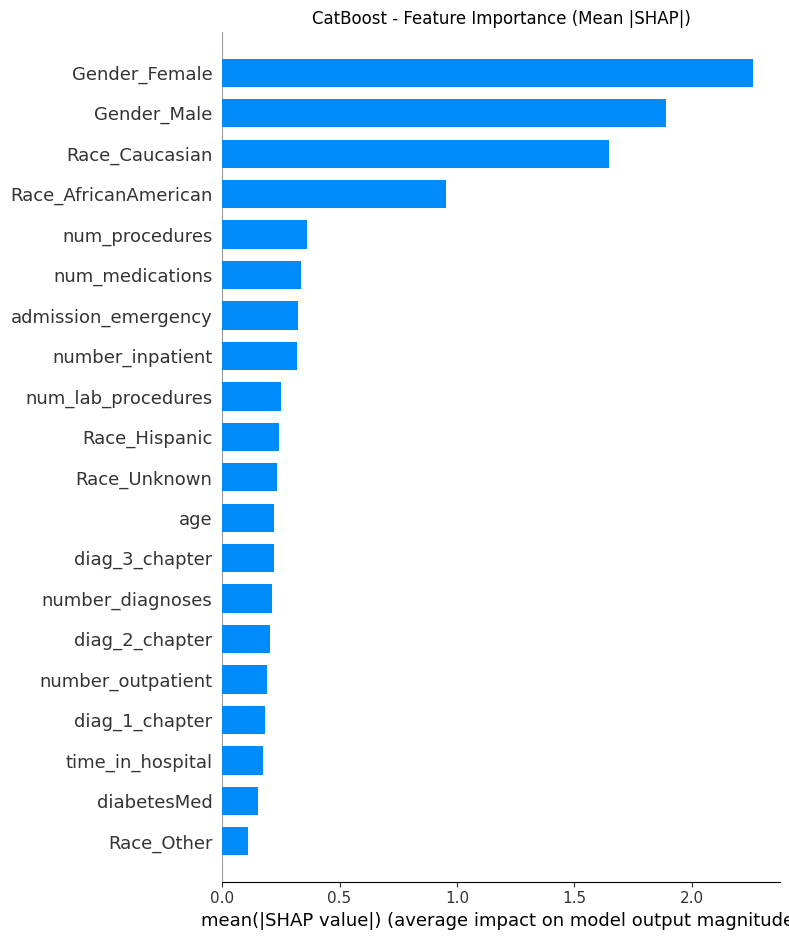

✓ Summary plot generated



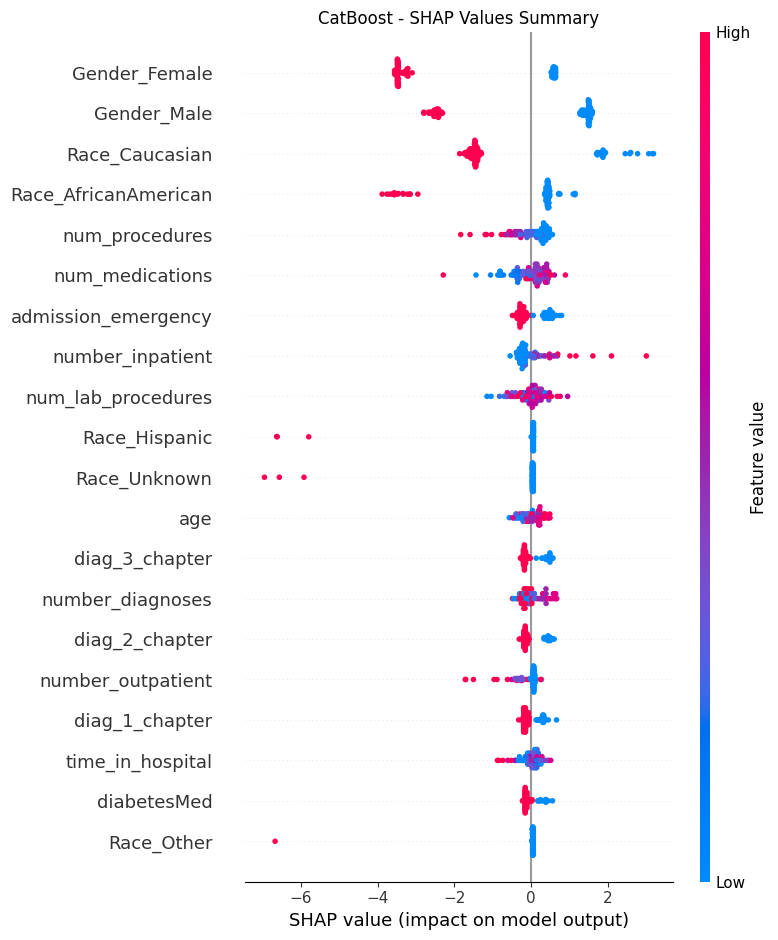

✓ Detailed summary plot generated

4. Individual Prediction Explanations (Force Plots)
----------------------------------------------------------------------
Error in force plot analysis: name 'explainer_rf' is not defined

5. Feature Dependence Analysis
----------------------------------------------------------------------
Error in dependence plot analysis: name 'shap_values_rf' is not defined

6. Feature Importance Comparison Across Models
----------------------------------------------------------------------
Error in feature importance comparison: name 'shap_values_rf' is not defined

7. SHAP Analysis Summary Statistics
----------------------------------------------------------------------
Error in summary statistics: name 'shap_values_rf' is not defined

SHAP analysis complete!


<Figure size 1400x400 with 0 Axes>

In [68]:
import shap
import matplotlib.pyplot as plt
import numpy as np

print("=" * 70)
print("SHAP Explainability Analysis")
print("=" * 70 + "\n")

# Create a sample of data for faster SHAP computation
sample_size = min(100, len(X_valid))
X_sample = X_valid.iloc[:sample_size]
y_sample = y_valid.iloc[:sample_size]

print(f"Using {sample_size} samples for SHAP analysis\n")

# ============================================================================
# 1. RANDOM FOREST (HP TUNED) - SHAP Analysis
# ============================================================================
print("1. RANDOM FOREST (HP TUNED) - SHAP Explainability")
print("-" * 70)

try:
    # Create SHAP explainer for Random Forest
    explainer_rf = shap.TreeExplainer(rf_hp)
    shap_values_rf = explainer_rf.shap_values(X_sample)
    
    # For binary classification, take class 1 (positive class) explanations
    if isinstance(shap_values_rf, list):
        shap_values_rf = shap_values_rf[1]
    
    # Summary plot
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values_rf, X_sample, plot_type="bar", show=False)
    plt.title("Random Forest (HP Tuned) - Feature Importance (Mean |SHAP|)")
    plt.tight_layout()
    plt.show()
    
    print("✓ Summary plot generated\n")
    
    # Detailed summary plot (shows individual impact)
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values_rf, X_sample, show=False)
    plt.title("Random Forest (HP Tuned) - SHAP Values Summary")
    plt.tight_layout()
    plt.show()
    
    print("✓ Detailed summary plot generated\n")
    
except Exception as e:
    print(f"Error in Random Forest SHAP analysis: {e}\n")

# ============================================================================
# 2. XGBOOST (HP TUNED) - SHAP Analysis
# ============================================================================
print("2. XGBOOST (HP TUNED) - SHAP Explainability")
print("-" * 70)

try:
    # Create SHAP explainer for XGBoost
    explainer_xgb = shap.TreeExplainer(xgb_hp)
    shap_values_xgb = explainer_xgb.shap_values(X_sample)
    
    # XGBoost returns array directly
    if isinstance(shap_values_xgb, list):
        shap_values_xgb = shap_values_xgb[1] if len(shap_values_xgb) > 1 else shap_values_xgb[0]
    
    # Summary plot
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values_xgb, X_sample, plot_type="bar", show=False)
    plt.title("XGBoost (HP Tuned) - Feature Importance (Mean |SHAP|)")
    plt.tight_layout()
    plt.show()
    
    print("✓ Summary plot generated\n")
    
    # Detailed summary plot
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values_xgb, X_sample, show=False)
    plt.title("XGBoost (HP Tuned) - SHAP Values Summary")
    plt.tight_layout()
    plt.show()
    
    print("✓ Detailed summary plot generated\n")
    
except Exception as e:
    print(f"Error in XGBoost SHAP analysis: {e}\n")

# ============================================================================
# 3. CATBOOST - SHAP Analysis
# ============================================================================
print("3. CATBOOST - SHAP Explainability")
print("-" * 70)

try:
    # Create SHAP explainer for CatBoost
    explainer_catb = shap.TreeExplainer(catb)
    shap_values_catb = explainer_catb.shap_values(X_sample)
    
    # Handle CatBoost output
    if isinstance(shap_values_catb, list):
        shap_values_catb = shap_values_catb[1] if len(shap_values_catb) > 1 else shap_values_catb[0]
    
    # Summary plot
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values_catb, X_sample, plot_type="bar", show=False)
    plt.title("CatBoost - Feature Importance (Mean |SHAP|)")
    plt.tight_layout()
    plt.show()
    
    print("✓ Summary plot generated\n")
    
    # Detailed summary plot
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values_catb, X_sample, show=False)
    plt.title("CatBoost - SHAP Values Summary")
    plt.tight_layout()
    plt.show()
    
    print("✓ Detailed summary plot generated\n")
    
except Exception as e:
    print(f"Error in CatBoost SHAP analysis: {e}\n")

# ============================================================================
# 4. Individual Prediction Explanations (Force Plot)
# ============================================================================
print("4. Individual Prediction Explanations (Force Plots)")
print("-" * 70)

try:
    # Random Forest - First prediction
    plt.figure(figsize=(14, 4))
    shap.force_plot(
        explainer_rf.expected_value[1] if isinstance(explainer_rf.expected_value, np.ndarray) else explainer_rf.expected_value,
        shap_values_rf[0],
        X_sample.iloc[0],
        matplotlib=True,
        show=False
    )
    plt.title(f"Random Forest - Prediction Explanation (Sample 1)")
    plt.tight_layout()
    plt.show()
    
    print("✓ Force plot generated for Random Forest\n")
    
except Exception as e:
    print(f"Error in force plot analysis: {e}\n")

# ============================================================================
# 5. Feature Dependence Plots
# ============================================================================
print("5. Feature Dependence Analysis")
print("-" * 70)

try:
    # Get top 5 most important features from Random Forest SHAP values
    feature_importance = np.abs(shap_values_rf).mean(axis=0)
    top_features_idx = np.argsort(feature_importance)[-5:][::-1]
    top_features = X_sample.columns[top_features_idx]
    
    # Create dependence plots for top 3 features
    for i, feature_idx in enumerate(top_features_idx[:3]):
        plt.figure(figsize=(10, 6))
        shap.dependence_plot(
            feature_idx,
            shap_values_rf,
            X_sample,
            feature_names=X_sample.columns,
            show=False
        )
        plt.title(f"Random Forest - Dependence Plot: {X_sample.columns[feature_idx]}")
        plt.tight_layout()
        plt.show()
    
    print(f"✓ Top 5 Most Important Features: {', '.join(top_features.tolist())}\n")
    
except Exception as e:
    print(f"Error in dependence plot analysis: {e}\n")

# ============================================================================
# 6. Feature Importance Comparison
# ============================================================================
print("6. Feature Importance Comparison Across Models")
print("-" * 70)

try:
    # Calculate mean absolute SHAP values for each model
    feature_importance_rf = np.abs(shap_values_rf).mean(axis=0)
    feature_importance_xgb = np.abs(shap_values_xgb).mean(axis=0)
    feature_importance_catb = np.abs(shap_values_catb).mean(axis=0)
    
    # Create comparison dataframe
    feature_comparison = pd.DataFrame({
        'Feature': X_sample.columns,
        'Random Forest': feature_importance_rf,
        'XGBoost': feature_importance_xgb,
        'CatBoost': feature_importance_catb
    }).sort_values('Random Forest', ascending=False).head(10)
    
    print("Top 10 Features by Random Forest SHAP Values:")
    print(feature_comparison.to_string(index=False))
    print()
    
    # Visualization
    fig, ax = plt.subplots(figsize=(12, 6))
    x = np.arange(len(feature_comparison))
    width = 0.25
    
    ax.bar(x - width, feature_comparison['Random Forest'], width, label='Random Forest', alpha=0.8)
    ax.bar(x, feature_comparison['XGBoost'], width, label='XGBoost', alpha=0.8)
    ax.bar(x + width, feature_comparison['CatBoost'], width, label='CatBoost', alpha=0.8)
    
    ax.set_xlabel('Features')
    ax.set_ylabel('Mean |SHAP Value|')
    ax.set_title('Feature Importance Comparison - Top 10 Features')
    ax.set_xticks(x)
    ax.set_xticklabels(feature_comparison['Feature'], rotation=45, ha='right')
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    print("✓ Feature importance comparison plot generated\n")
    
except Exception as e:
    print(f"Error in feature importance comparison: {e}\n")

# ============================================================================
# 7. Summary Statistics
# ============================================================================
print("7. SHAP Analysis Summary Statistics")
print("-" * 70)

try:
    print(f"Random Forest - Mean |SHAP|: {np.abs(shap_values_rf).mean():.4f}")
    print(f"XGBoost - Mean |SHAP|: {np.abs(shap_values_xgb).mean():.4f}")
    print(f"CatBoost - Mean |SHAP|: {np.abs(shap_values_catb).mean():.4f}")
    print()
    
    print("Interpretation Guide:")
    print("- Larger |SHAP| values indicate features with stronger influence on predictions")
    print("- Red points: high feature values push prediction towards positive class")
    print("- Blue points: low feature values push prediction towards positive class")
    print("- Force plots: show which features push prediction left (negative) or right (positive)")
    print()
    
except Exception as e:
    print(f"Error in summary statistics: {e}\n")

print("=" * 70)
print("SHAP analysis complete!")
print("=" * 70)